In [1]:
from get_data.get_data import get_merged_events
from statsbombpy import sb

MATCH_ID = 3788776

EVENTS_TO_ANALIZE = ['passes', 'carrys', 'ball_receipts', 'ball_recoverys', 'dribbles', 'blocks', 'clearances', 'duels',
'dispossesseds', 'errors', 'foul_committeds', 'foul_wons', 'half_ends', 'injury_stoppages', 'interceptions', 'miscontrols', 'shots']

events = get_merged_events(EVENTS_TO_ANALIZE, MATCH_ID)

events.head(5)

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,duration,related_events,event,match_id,possession_team_id,player_id,under_pressure,off_camera,counterpress,out
0,9e9ec22a-f1cf-4460-ba53-c786f7b05287,5,1,00:00:00.080,0,0,Pass,2,Sweden,From Kick Off,...,1.422263,[b3c8e55c-581c-4c68-b722-446903bbd574],"{'recipient': {'id': 3702, 'name': 'Victor Nil...",3788776,790,5617.0,,,,
1,b3c8e55c-581c-4c68-b722-446903bbd574,6,1,00:00:01.502,0,1,Ball Receipt*,2,Sweden,From Kick Off,...,,[9e9ec22a-f1cf-4460-ba53-c786f7b05287],,3788776,790,3702.0,,,,
2,f0280b81-7d48-4071-bd0e-c479ccda4a03,7,1,00:00:01.502,0,1,Carry,2,Sweden,From Kick Off,...,1.150845,"[470d2435-f5a4-46f9-aa0c-af2ce5e92f31, b3c8e55...","{'end_location': [36.8, 41.1]}",3788776,790,3702.0,,,,
3,470d2435-f5a4-46f9-aa0c-af2ce5e92f31,8,1,00:00:02.653,0,2,Pass,2,Sweden,From Kick Off,...,3.210068,[e7e53c4b-6ee1-4f04-9a41-c4d3906d072e],"{'recipient': {'id': 5612, 'name': 'Mikael Lus...",3788776,790,3702.0,,,,
4,e7e53c4b-6ee1-4f04-9a41-c4d3906d072e,9,1,00:00:05.863,0,5,Ball Receipt*,2,Sweden,From Kick Off,...,,[470d2435-f5a4-46f9-aa0c-af2ce5e92f31],,3788776,790,5612.0,,,,


In [2]:
frames = sb.frames(MATCH_ID, fmt='dataframe')
frames.to_csv('test.csv')
frames.head(5) # type: ignore

,id,visible_area,match_id,teammate,actor,keeper,location,distance_from_edge_of_visible_area
0,c249a6c9-9fa2-4b53-b1f5-865a60505c70,"[27.8019284858234, 80.0, 39.8323195813396, 30....",3788776,False,False,False,"[69.40095223157572, 61.70312937775431]",5.379393
1,c249a6c9-9fa2-4b53-b1f5-865a60505c70,"[27.8019284858234, 80.0, 39.8323195813396, 30....",3788776,True,False,False,"[65.92739260158025, 61.276305145191095]",8.643000
2,c249a6c9-9fa2-4b53-b1f5-865a60505c70,"[27.8019284858234, 80.0, 39.8323195813396, 30....",3788776,False,False,False,"[63.18484011960767, 52.05911953046989]",9.047431
3,c249a6c9-9fa2-4b53-b1f5-865a60505c70,"[27.8019284858234, 80.0, 39.8323195813396, 30....",3788776,False,False,False,"[64.17685632346844, 68.96885331573115]",11.031147
4,c249a6c9-9fa2-4b53-b1f5-865a60505c70,"[27.8019284858234, 80.0, 39.8323195813396, 30....",3788776,True,False,False,"[61.766687286253514, 71.09766703738244]",8.902333


In [3]:
from dataframe_modify.add_positions import add_positions
from dataframe_modify.swap_perspective import swap_y
from dataframe_modify.swap_perspective import generalize_perspective
from dataframe_modify.grid_areas import add_grid_areas
from dataframe_modify.add_context import add_context
from sequences.get_sequences import get_sequences_by_possession

start_team = events['possession_team'][0]

events = add_context(events, frames)
events = add_positions(events)
events = generalize_perspective(events, start_team)
events = swap_y(events)
events = add_grid_areas(events)

sequences = get_sequences_by_possession(events)

In [4]:
sequences[0].to_csv('test.csv')

In [6]:
sequences[4].to_csv('test.csv')


Team: Sweden
1: Sebastian Larsson (Pass) <00:00:00.080>
2: Victor Nilsson Lindelöf (Ball Receipt*) <00:00:01.502>
2: Victor Nilsson Lindelöf (Carry) <00:00:01.502>
2: Victor Nilsson Lindelöf (Pass) <00:00:02.653>
3: Mikael Lustig (Ball Receipt*) <00:00:05.863>
3: Mikael Lustig (Pass) <00:00:05.863>
4: Robin Quaison (Ball Receipt*) <00:00:09.353>
4: Robin Quaison (Duel) <00:00:09.353>


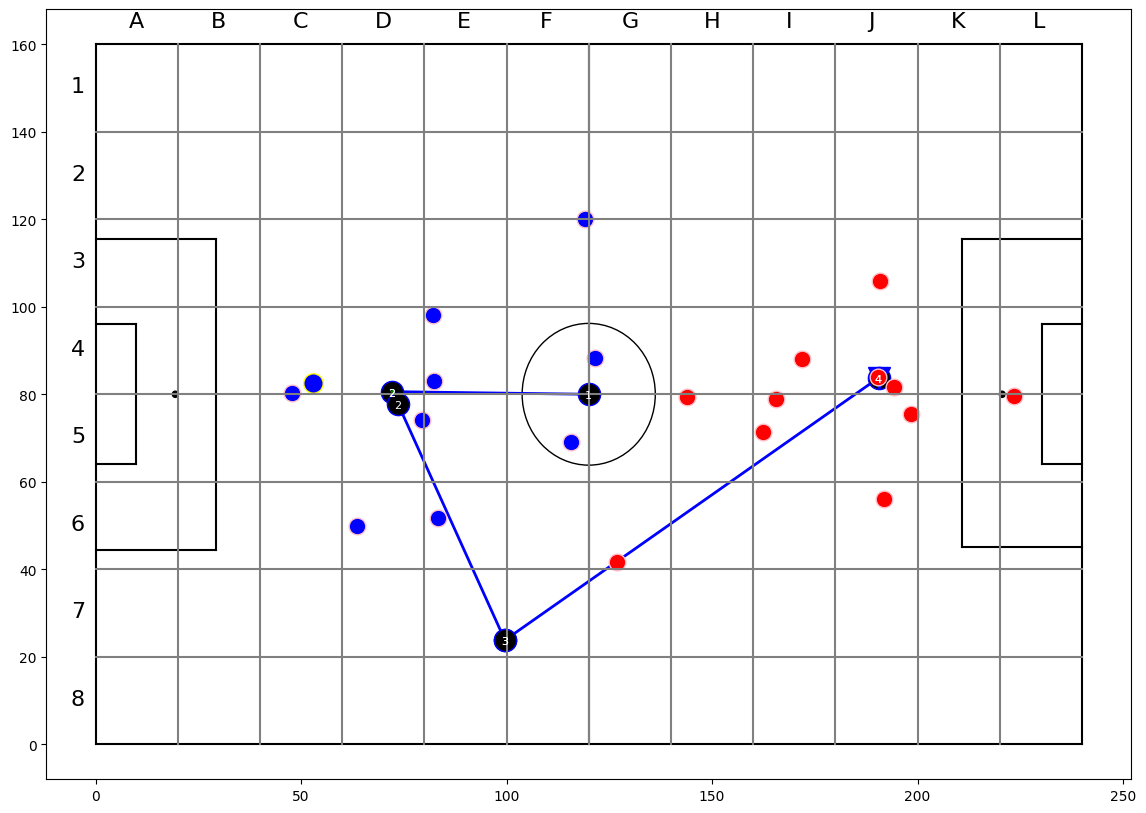

Team: Poland
1: Kamil Glik (Pass) <00:00:09.353>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:00:10.310>
2: Mateusz Andrzej Klich (Pass) <00:00:10.344>
3: Piotr Zieliński (Ball Receipt*) <00:00:11.479>
3: Piotr Zieliński (Carry) <00:00:11.479>
3: Piotr Zieliński (Pass) <00:00:13.421>
4: Robert Lewandowski (Ball Receipt*) <00:00:14.364>
4: Robert Lewandowski (Carry) <00:00:14.364>
4: Robert Lewandowski (Pass) <00:00:15.523>
5: Tymoteusz Puchacz (Ball Receipt*) <00:00:16.740>
5: Tymoteusz Puchacz (Carry) <00:00:16.740>
5: Tymoteusz Puchacz (Pass) <00:00:17.456>
6: Jan Bednarek (Ball Receipt*) <00:00:18.427>
6: Jan Bednarek (Carry) <00:00:18.427>
6: Jan Bednarek (Pass) <00:00:19.747>
7: Bartosz Bereszyński (Ball Receipt*) <00:00:21.153>
7: Bartosz Bereszyński (Carry) <00:00:21.153>
7: Bartosz Bereszyński (Pass) <00:00:25.168>
8: Kamil Glik (Ball Receipt*) <00:00:26.550>
8: Kamil Glik (Carry) <00:00:26.550>
8: Kamil Glik (Pass) <00:00:27.497>
9: Jan Bednarek (Ball Receipt*) <00:00:29.147>


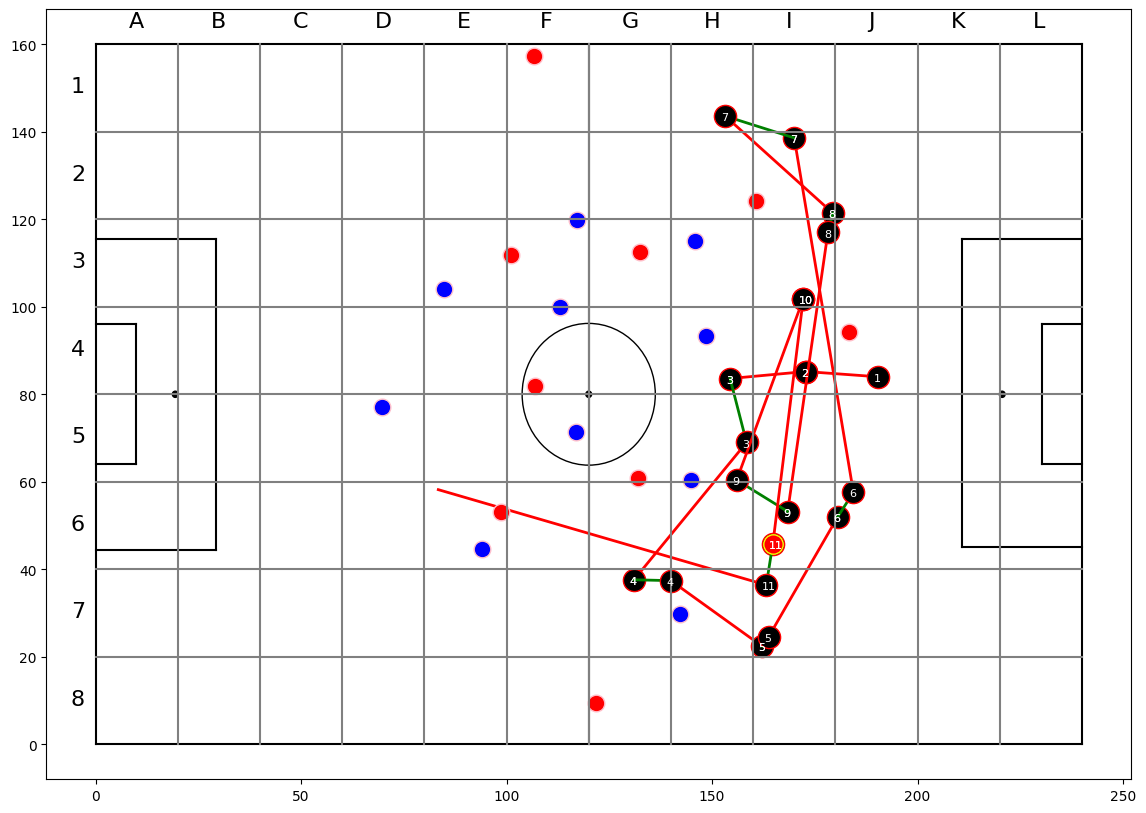

Team: Sweden
1: Victor Nilsson Lindelöf (Pass) <00:00:38.375>
2: Kristoffer Olsson (Ball Receipt*) <00:00:39.466>
2: Kristoffer Olsson (Pass) <00:00:39.466>
3: Mikael Lustig (Ball Receipt*) <00:00:40.562>
3: Mikael Lustig (Carry) <00:00:40.562>
3: Mikael Lustig (Pass) <00:00:42.468>


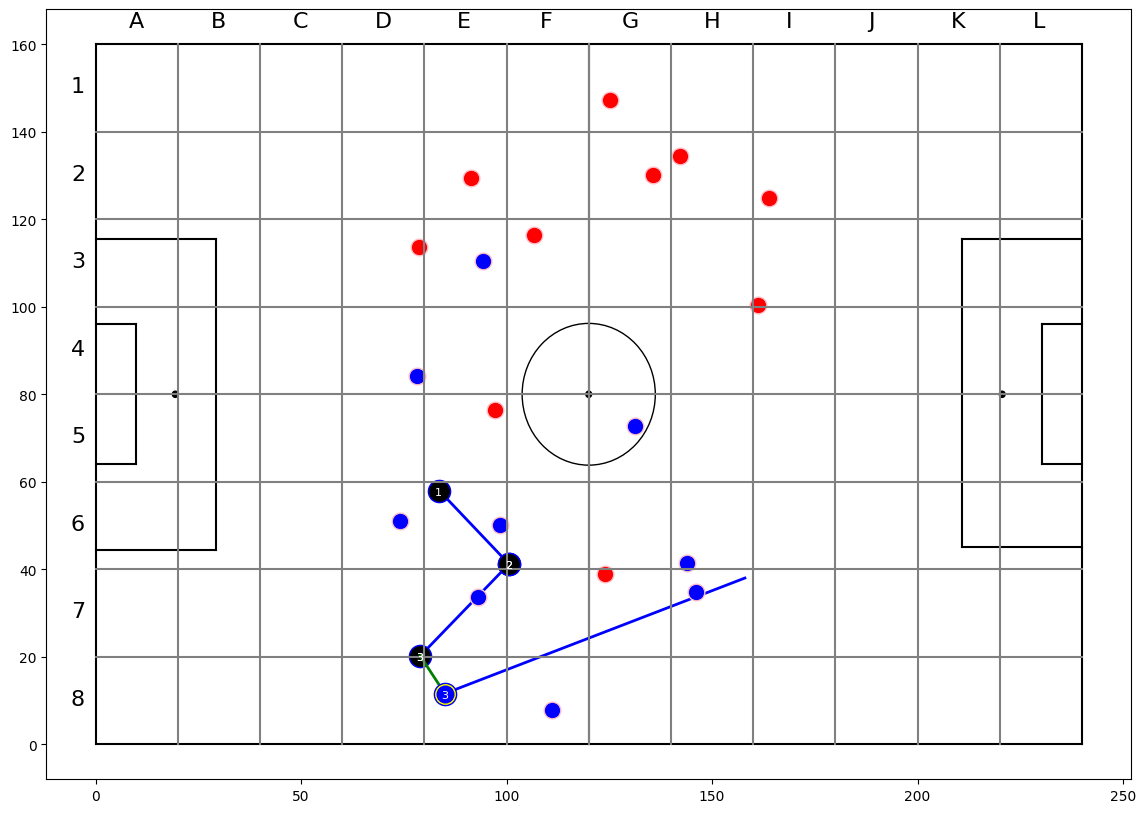

Team: Poland
1: Jan Bednarek (Pass) <00:00:44.270>
2: Grzegorz Krychowiak (Ball Receipt*) <00:00:45.101>
2: Grzegorz Krychowiak (Carry) <00:00:45.101>
2: Grzegorz Krychowiak (Pass) <00:00:46.473>
3: Tymoteusz Puchacz (Ball Receipt*) <00:00:47.194>
3: Tymoteusz Puchacz (Carry) <00:00:47.194>
3: Tymoteusz Puchacz (Pass) <00:00:47.847>
4: Mateusz Andrzej Klich (Ball Receipt*) <00:00:48.794>
4: Mateusz Andrzej Klich (Carry) <00:00:48.794>
4: Mateusz Andrzej Klich (Dispossessed) <00:00:50.138>
5: Mikael Lustig (Duel) <00:00:50.138>


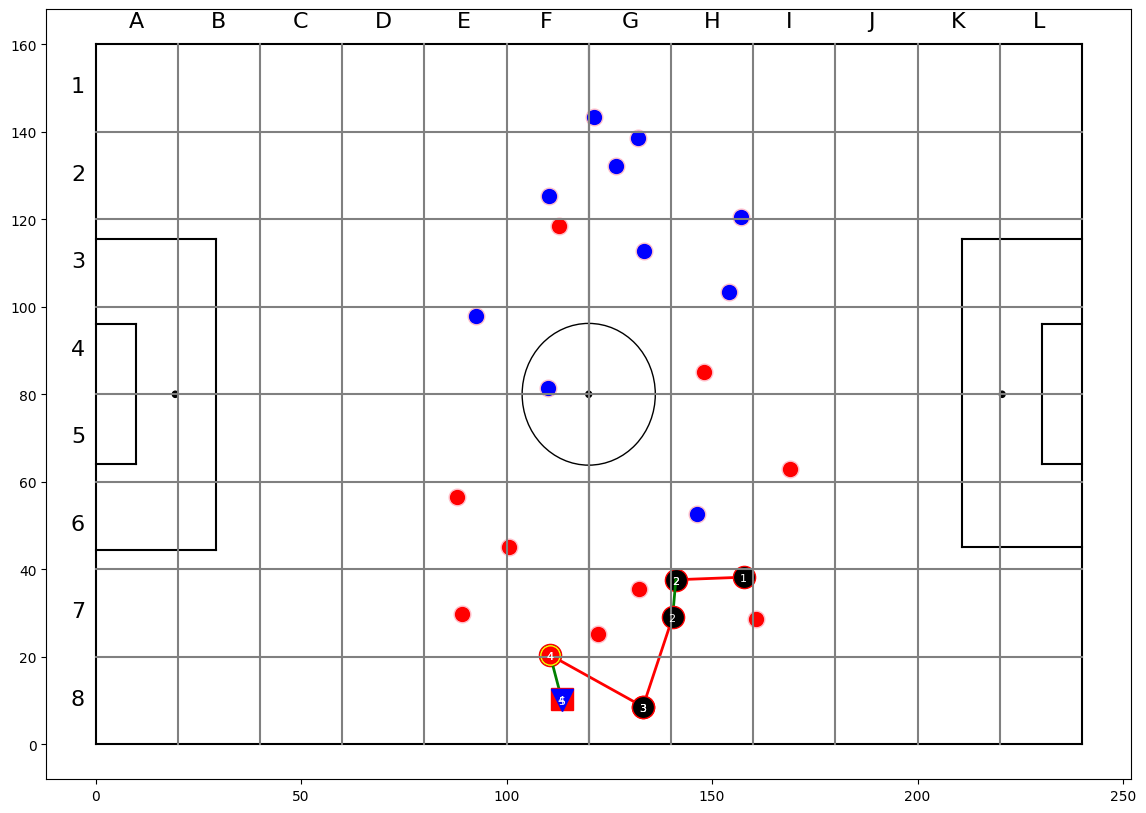

Team: Sweden
1: Mikael Lustig (Pass) <00:01:10.498>
2: Sebastian Larsson (Ball Receipt*) <00:01:11.479>
2: Sebastian Larsson (Pass) <00:01:11.479>
3: Mikael Lustig (Ball Receipt*) <00:01:12.472>
3: Mikael Lustig (Pass) <00:01:12.472>
4: Sebastian Larsson (Ball Receipt*) <00:01:13.070>
4: Sebastian Larsson (Pass) <00:01:13.070>
5: Mikael Lustig (Ball Receipt*) <00:01:14.119>
5: Mikael Lustig (Carry) <00:01:14.119>
5: Mikael Lustig (Pass) <00:01:15.083>
6: Alexander Isak (Ball Receipt*) <00:01:16.569>
6: Alexander Isak (Carry) <00:01:16.569>
6: Alexander Isak (Pass) <00:01:16.577>
7: Emil Peter Forsberg (Ball Receipt*) <00:01:17.827>
7: Emil Peter Forsberg (Carry) <00:01:17.827>
7: Emil Peter Forsberg (Pass) <00:01:17.830>
8: Alexander Isak (Ball Receipt*) <00:01:18.888>
8: Alexander Isak (Carry) <00:01:18.888>
8: Alexander Isak (Dispossessed) <00:01:19.168>
9: Kamil Glik (Duel) <00:01:19.168>
10: Emil Peter Forsberg (Pass) <00:01:19.483>
11: Alexander Isak (Ball Receipt*) <00:01:20.025>

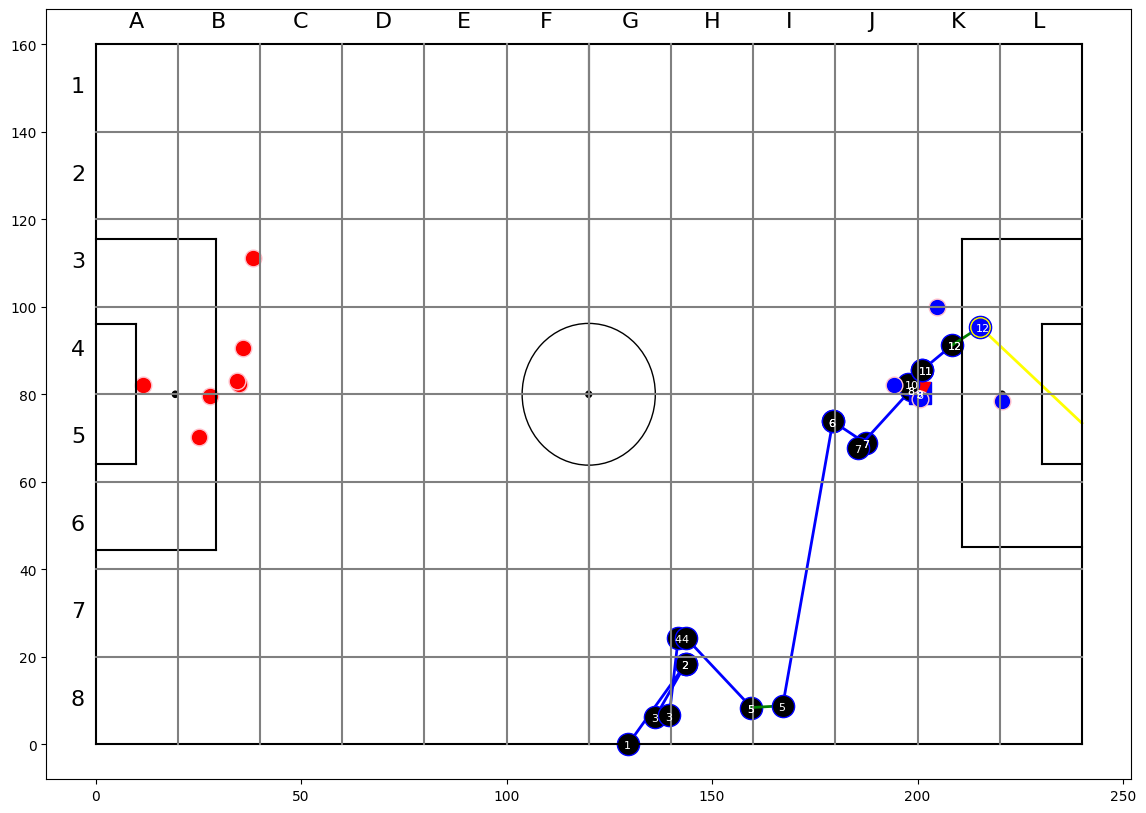

Team: Poland
1: Robert Lewandowski (Pass) <00:02:17.362>
2: Kamil Glik (Ball Receipt*) <00:02:19.016>
2: Kamil Glik (Pass) <00:02:21.722>
3: Jan Bednarek (Ball Receipt*) <00:02:23.028>
3: Jan Bednarek (Carry) <00:02:23.028>
3: Jan Bednarek (Pass) <00:02:25.583>
4: Kamil Glik (Ball Receipt*) <00:02:27.086>
4: Kamil Glik (Carry) <00:02:27.086>
4: Kamil Glik (Pass) <00:02:30.217>
5: Jan Bednarek (Ball Receipt*) <00:02:32.147>
5: Jan Bednarek (Carry) <00:02:32.147>
5: Jan Bednarek (Pass) <00:02:33.891>
6: Robert Lewandowski (Ball Receipt*) <00:02:36.609>


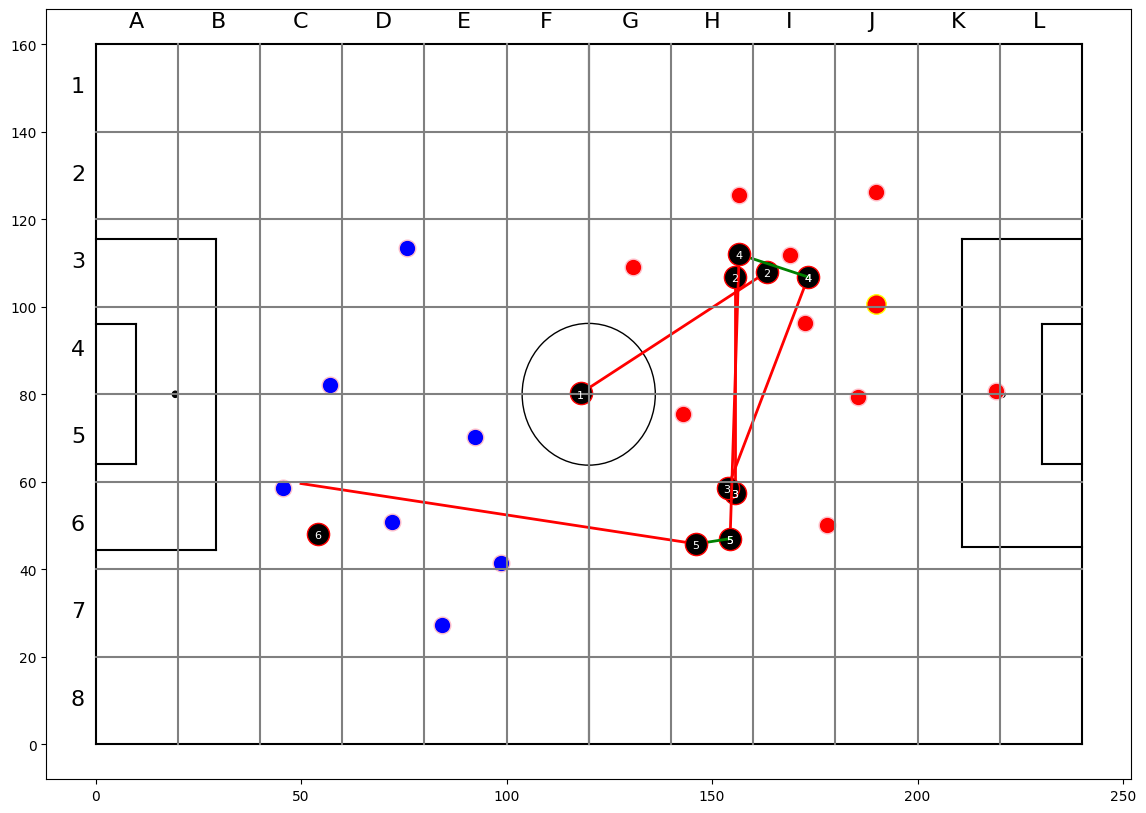

Team: Sweden
1: Victor Nilsson Lindelöf (Pass) <00:02:36.609>
2: Mikael Lustig (Ball Receipt*) <00:02:38.606>
2: Mikael Lustig (Carry) <00:02:38.606>
2: Mikael Lustig (Pass) <00:02:40.897>
3: Alexander Isak (Ball Receipt*) <00:02:43.264>
3: Alexander Isak (Duel) <00:02:43.264>
4: Kamil Glik (Pass) <00:02:43.264>


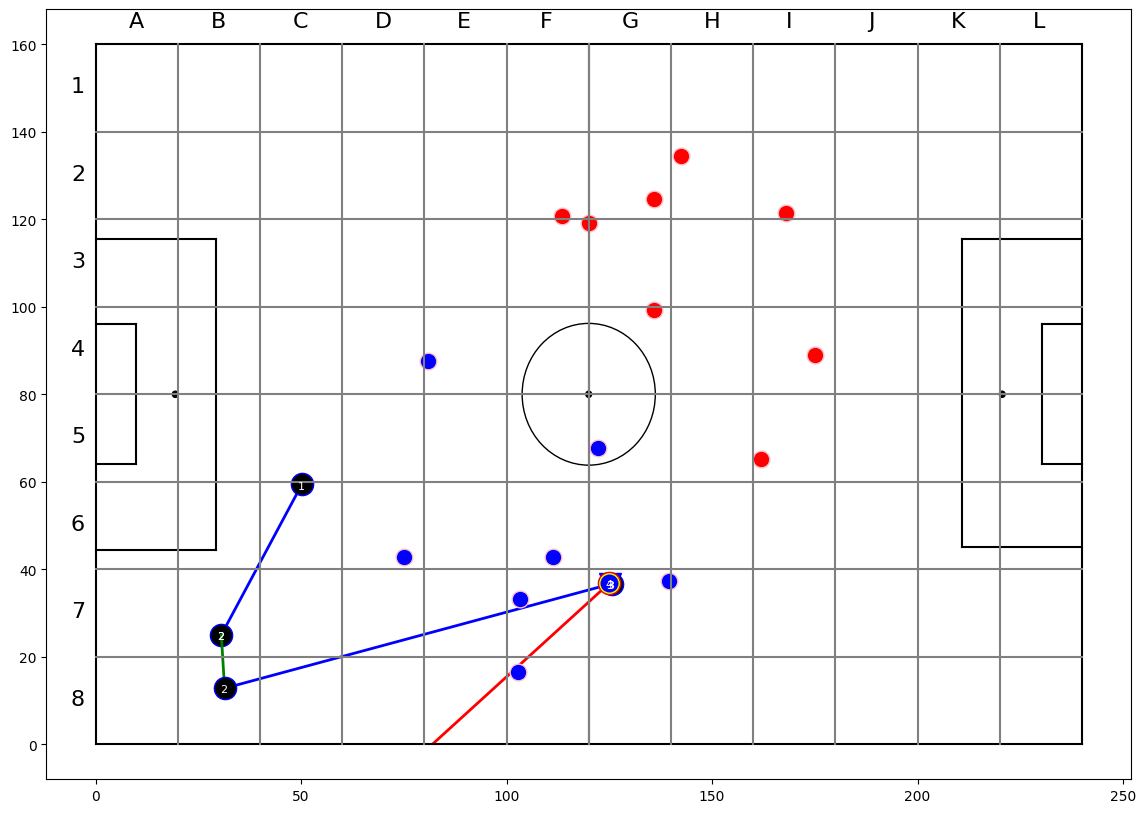

Team: Sweden
1: Mikael Lustig (Pass) <00:02:58.958>
2: Sebastian Larsson (Ball Receipt*) <00:03:00.252>
2: Sebastian Larsson (Carry) <00:03:00.252>
2: Sebastian Larsson (Pass) <00:03:00.268>
3: Mikael Lustig (Ball Receipt*) <00:03:01.146>
3: Mikael Lustig (Pass) <00:03:01.146>
4: Sebastian Larsson (Ball Receipt*) <00:03:01.294>
5: Piotr Zieliński (Block) <00:03:01.294>


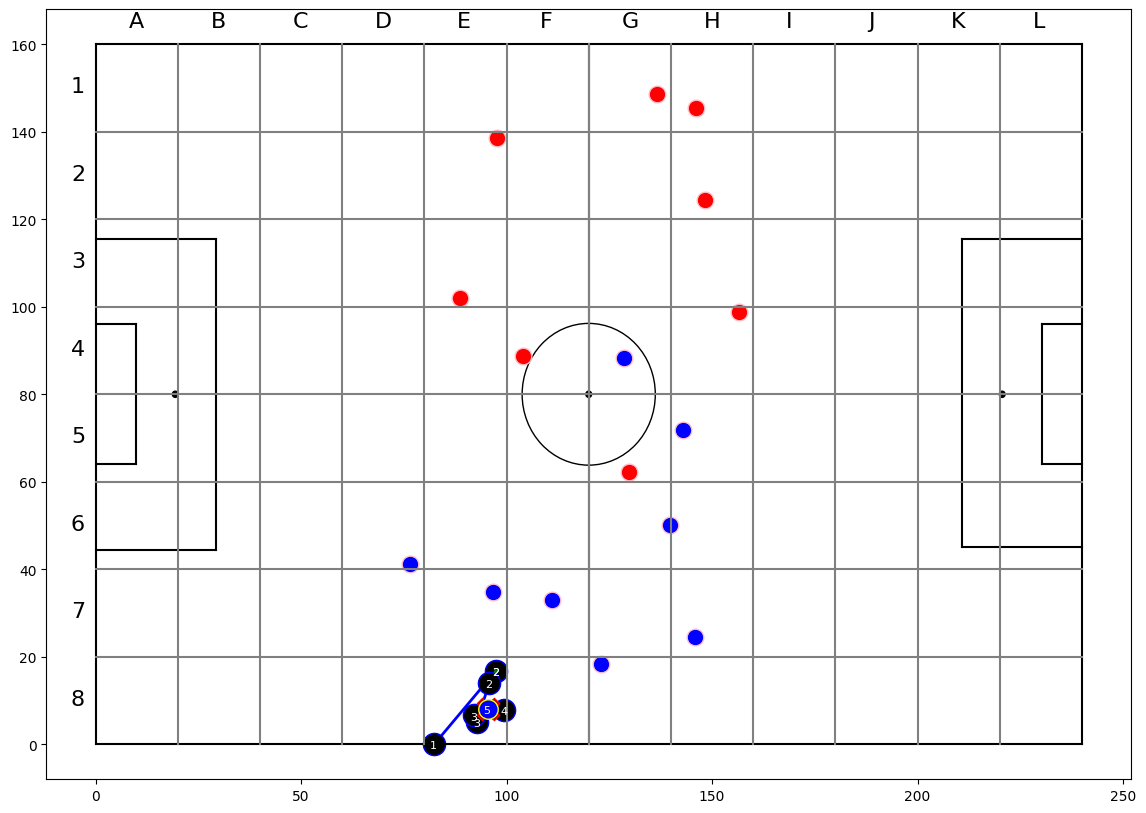

Team: Sweden
1: Mikael Lustig (Pass) <00:03:11.677>
2: Kristoffer Olsson (Ball Receipt*) <00:03:12.556>
2: Kristoffer Olsson (Pass) <00:03:12.556>
3: Mikael Lustig (Ball Receipt*) <00:03:13.491>
3: Mikael Lustig (Pass) <00:03:13.491>
4: Robin Quaison (Ball Receipt*) <00:03:16.503>
5: Kamil Glik (Pass) <00:03:16.503>
6: Tymoteusz Puchacz (Ball Receipt*) <00:03:18.134>
6: Tymoteusz Puchacz (Carry) <00:03:18.134>
6: Tymoteusz Puchacz (Pass) <00:03:19.771>
7: Marcus Andreas Danielsson (Pass) <00:03:23.681>
8: Robin Quaison (Ball Receipt*) <00:03:26.064>
9: Jan Bednarek (Duel) <00:03:26.064>
10: Robin Quaison (Pass) <00:03:26.064>
11: Emil Peter Forsberg (Ball Receipt*) <00:03:26.994>
11: Emil Peter Forsberg (Carry) <00:03:26.994>
11: Emil Peter Forsberg (Pass) <00:03:28.076>
12: Ludwig Augustinsson (Ball Receipt*) <00:03:32.879>
12: Ludwig Augustinsson (Carry) <00:03:32.879>
12: Ludwig Augustinsson (Pass) <00:03:34.011>
13: Albin Ekdal (Ball Receipt*) <00:03:35.616>
13: Albin Ekdal (Carry)

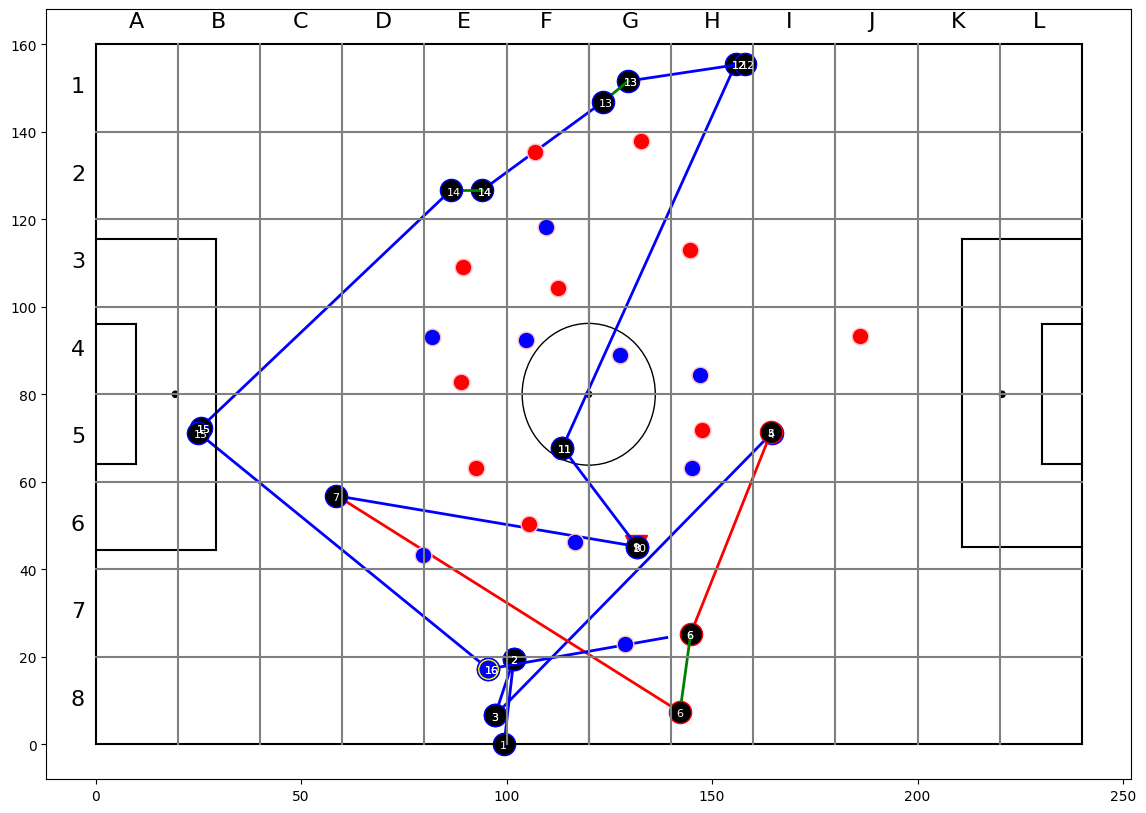

Team: Poland
1: Jan Bednarek (Pass) <00:03:53.358>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:03:54.025>
2: Mateusz Andrzej Klich (Carry) <00:03:54.025>
2: Mateusz Andrzej Klich (Pass) <00:03:54.063>
3: Grzegorz Krychowiak (Ball Receipt*) <00:03:55.019>
3: Grzegorz Krychowiak (Pass) <00:03:55.019>


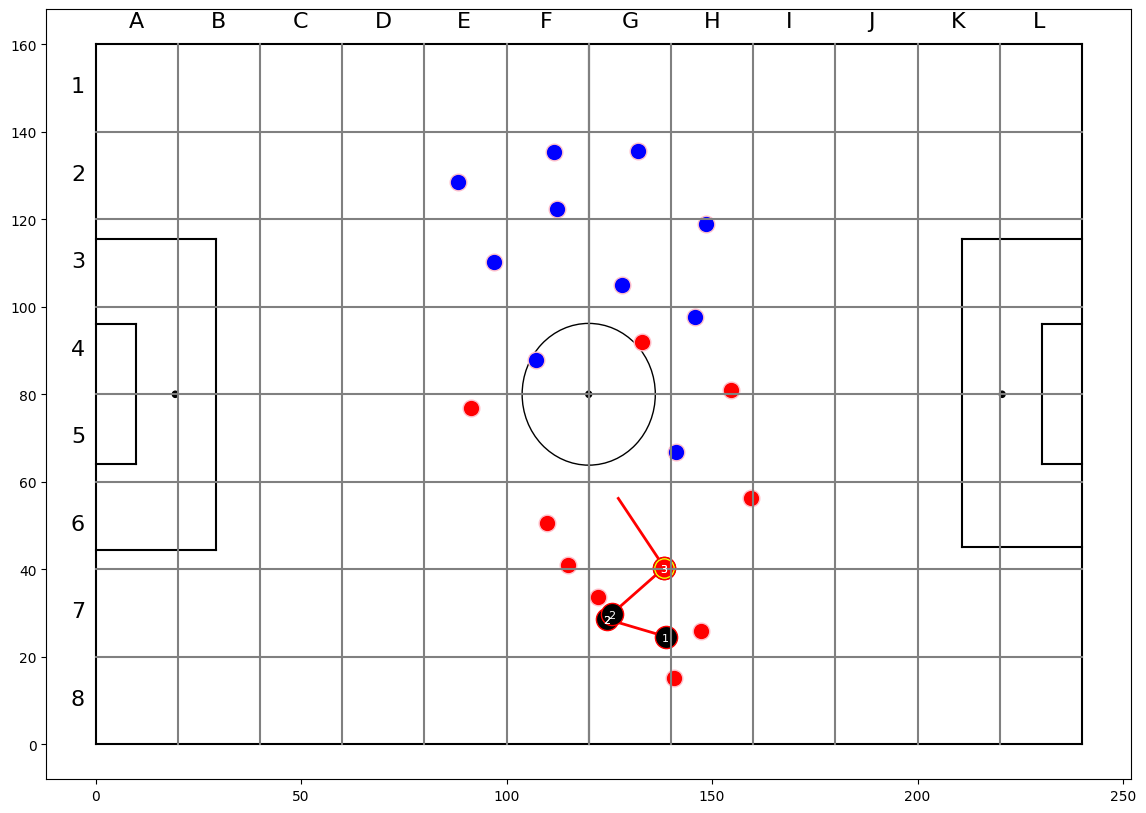

Team: Sweden
1: Kristoffer Olsson (Pass) <00:03:57.065>
2: Emil Peter Forsberg (Ball Receipt*) <00:03:58.111>
2: Emil Peter Forsberg (Carry) <00:03:58.111>
2: Emil Peter Forsberg (Pass) <00:04:01.108>
3: Ludwig Augustinsson (Ball Receipt*) <00:04:02.667>
3: Ludwig Augustinsson (Carry) <00:04:02.667>
3: Ludwig Augustinsson (Pass) <00:04:06.061>
4: Kristoffer Olsson (Ball Receipt*) <00:04:06.841>
4: Kristoffer Olsson (Carry) <00:04:06.841>
4: Kristoffer Olsson (Dispossessed) <00:04:06.879>
5: Bartosz Bereszyński (Duel) <00:04:06.879>
6: Kristoffer Olsson (Pass) <00:04:08.905>
7: Albin Ekdal (Ball Receipt*) <00:04:10.392>
7: Albin Ekdal (Pass) <00:04:10.392>
8: Ludwig Augustinsson (Ball Receipt*) <00:04:11.705>
8: Ludwig Augustinsson (Carry) <00:04:11.705>
8: Ludwig Augustinsson (Pass) <00:04:13.227>
9: Emil Peter Forsberg (Ball Receipt*) <00:04:13.915>
9: Emil Peter Forsberg (Carry) <00:04:13.915>
9: Emil Peter Forsberg (Dispossessed) <00:04:15.120>
10: Grzegorz Krychowiak (Duel) <00:04:

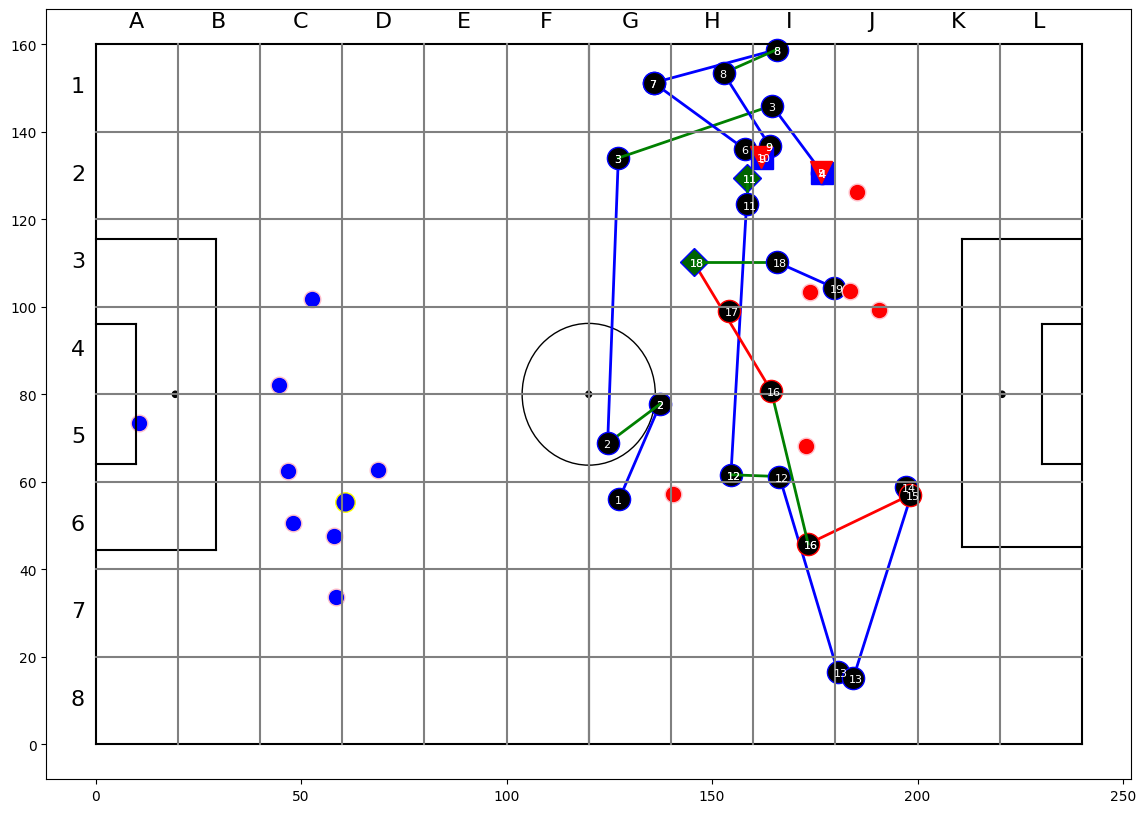

Team: Poland
1: Grzegorz Krychowiak (Interception) <00:04:34.047>
1: Grzegorz Krychowiak (Carry) <00:04:34.047>
1: Grzegorz Krychowiak (Pass) <00:04:35.567>
2: Karol Świderski (Ball Receipt*) <00:04:36.790>
2: Karol Świderski (Carry) <00:04:36.790>
2: Karol Świderski (Pass) <00:04:37.520>
3: Piotr Zieliński (Ball Receipt*) <00:04:38.289>
3: Piotr Zieliński (Carry) <00:04:38.289>
3: Piotr Zieliński (Pass) <00:04:39.143>
4: Kamil Jóźwiak (Ball Receipt*) <00:04:42.801>
4: Kamil Jóźwiak (Miscontrol) <00:04:42.801>


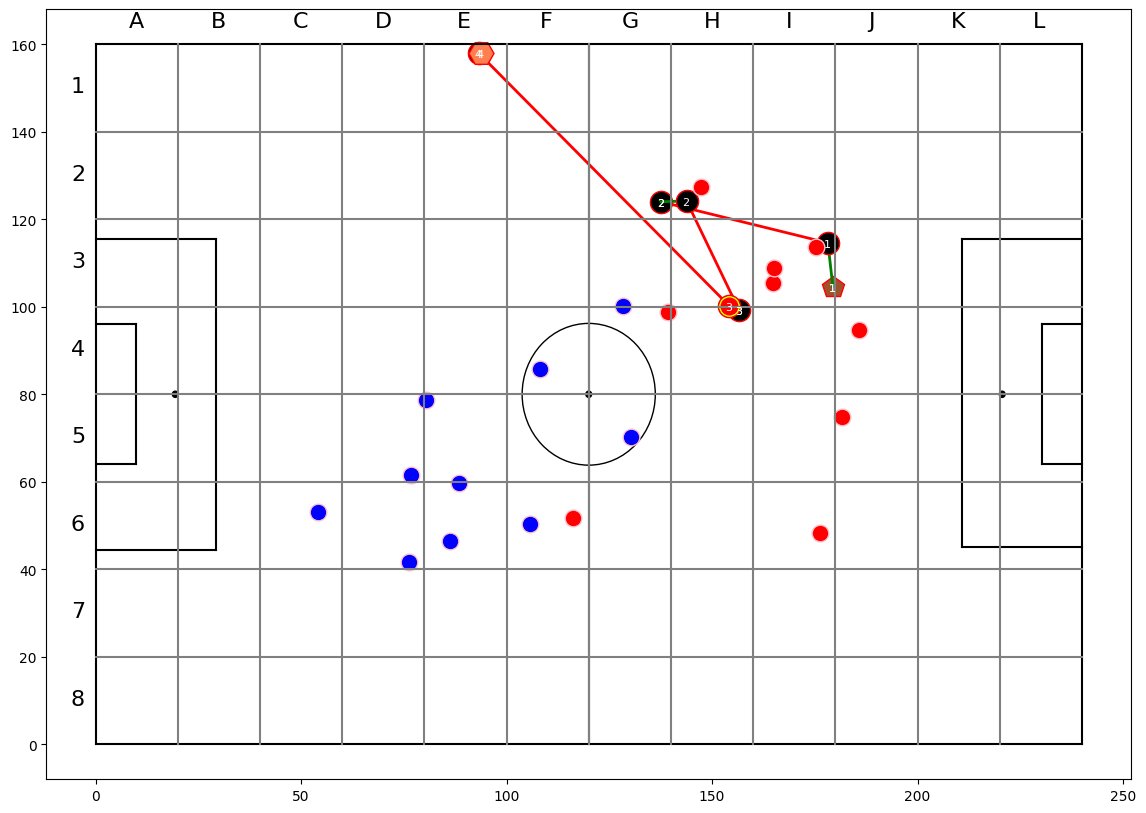

Team: Sweden
1: Ludwig Augustinsson (Pass) <00:05:11.130>
2: Alexander Isak (Ball Receipt*) <00:05:12.389>
2: Alexander Isak (Duel) <00:05:12.389>


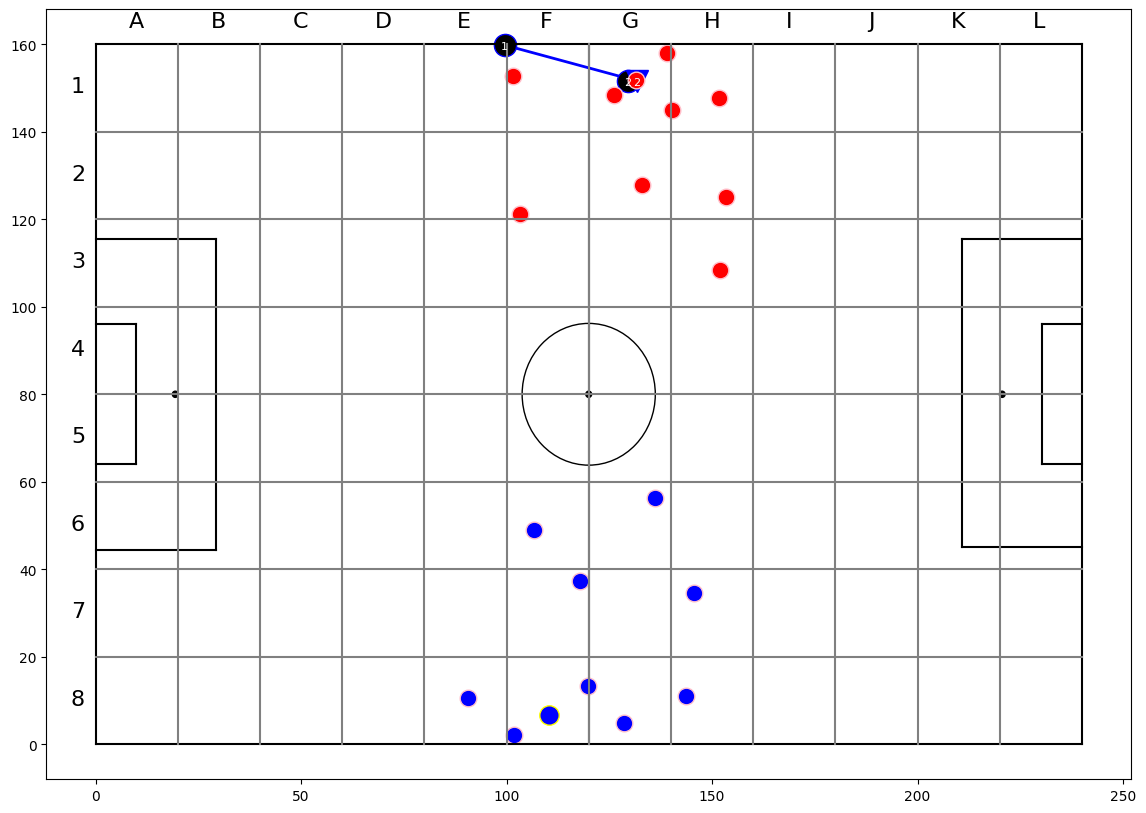

Team: Poland
1: Kamil Glik (Pass) <00:05:12.389>
2: Jan Bednarek (Ball Receipt*) <00:05:14.149>
2: Jan Bednarek (Pass) <00:05:14.172>
3: Mateusz Andrzej Klich (Ball Receipt*) <00:05:14.736>
4: Kristoffer Olsson (Interception) <00:05:14.736>
5: Grzegorz Krychowiak (Pass) <00:05:15.315>
6: Albin Ekdal (Pass) <00:05:16.378>
7: Robin Quaison (Ball Receipt*) <00:05:19.207>
8: Jan Bednarek (Pass) <00:05:19.207>
9: Grzegorz Krychowiak (Ball Receipt*) <00:05:20.278>
9: Grzegorz Krychowiak (Pass) <00:05:20.278>
10: Mateusz Andrzej Klich (Ball Receipt*) <00:05:22.914>
10: Mateusz Andrzej Klich (Carry) <00:05:22.914>
10: Mateusz Andrzej Klich (Pass) <00:05:24.673>
11: Grzegorz Krychowiak (Ball Receipt*) <00:05:25.220>
11: Grzegorz Krychowiak (Carry) <00:05:25.220>
11: Grzegorz Krychowiak (Pass) <00:05:26.948>
12: Bartosz Bereszyński (Ball Receipt*) <00:05:27.918>
12: Bartosz Bereszyński (Carry) <00:05:27.918>
12: Bartosz Bereszyński (Pass) <00:05:29.227>
13: Karol Świderski (Ball Receipt*) <00:05

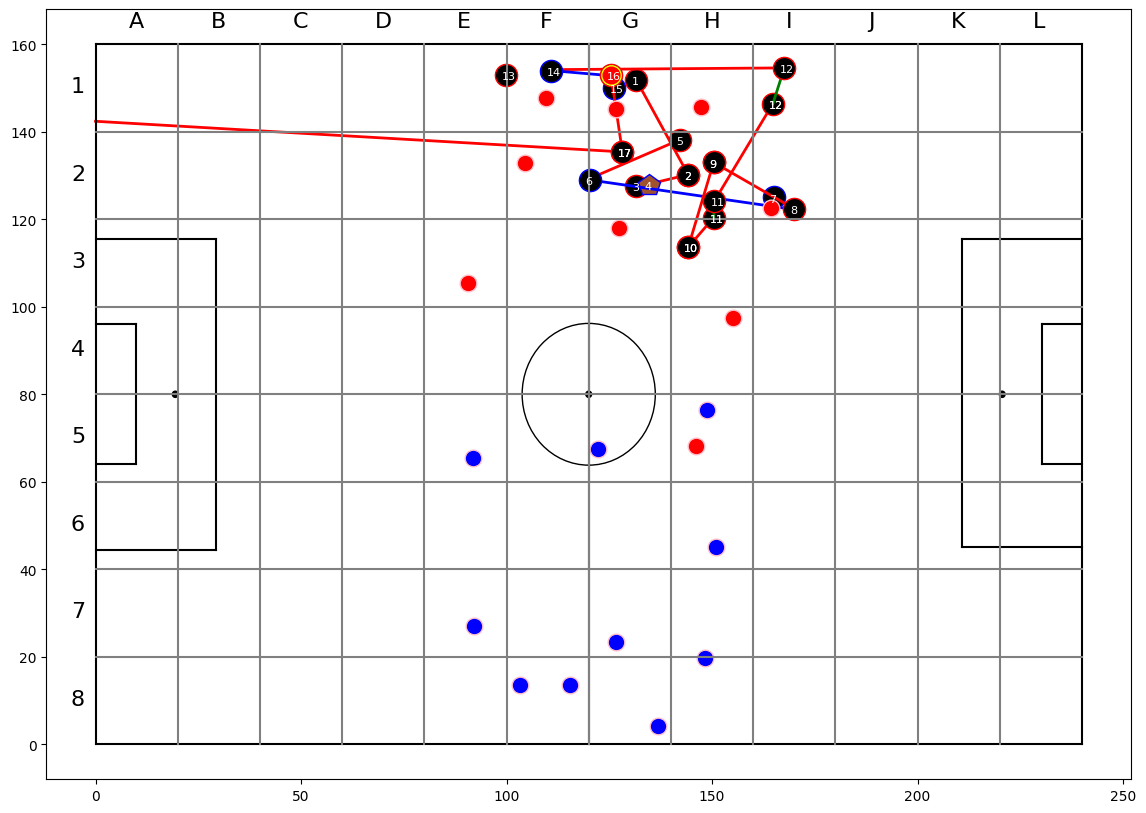

Team: Sweden
1: Robin Olsen (Pass) <00:06:07.179>
2: Sebastian Larsson (Ball Receipt*) <00:06:11.801>
2: Sebastian Larsson (Pass) <00:06:11.840>
3: Tymoteusz Puchacz (Duel) <00:06:11.840>
4: Alexander Isak (Ball Receipt*) <00:06:13.887>
5: Jan Bednarek (Interception) <00:06:13.887>


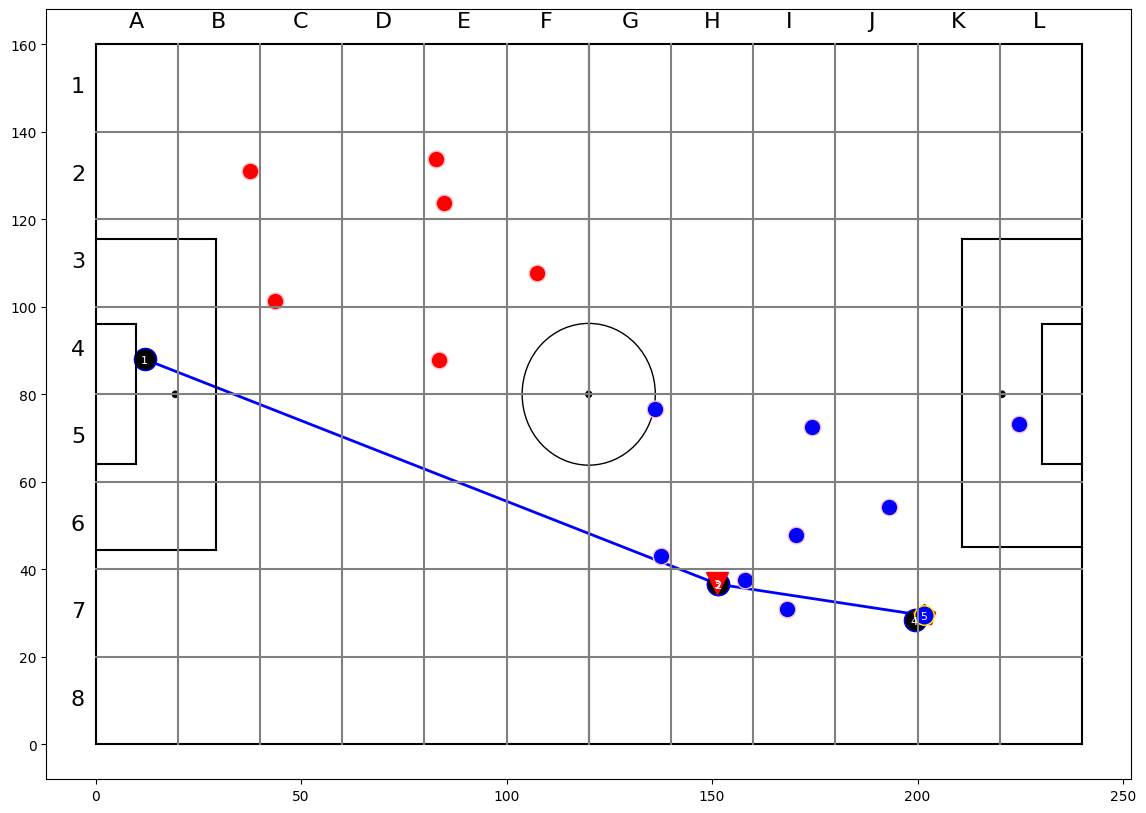

In [5]:
from draw.draw_sequences import draw_events_sequence

for i, s in enumerate(sequences):
    if i == 15:
        break
    draw_events_sequence(s, start_team, 12, 8, scale=2)